# 12-Month Probabilistic CLV: BG/NBD and Gamma-Gamma

### Objective

This notebook estimates 12-month customer lifetime value using probabilistic models that describe repeat purchasing behavior and customer spend in a transparent, interpretable way.

Rather than relying on short-term prediction alone, this approach models the underlying purchasing process by separating:

1. **Purchase frequency:** How often customers buy (BG/NBD model).
2. **Monetary value:** How much they spend when they do (Gamma-Gamma model).

This structure aligns with how marketing and CRM teams reason about customer value and supports long-term planning and prioritization.

The probabilistic approach is stable, data-efficient, and interpretable, making it well-suited for strategic decisions such as customer prioritization, retention planning, and budget allocation.

### Output

The resulting 12-month probabilistic CLV estimates are exported as a customer-level dataset for downstream segmentation, targeting simulations, and BI reporting.

## Load Cleaned Transactions Dataset

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Color palette for visuals
COLOR_PRIMARY = "#2E4057"      # Dark slate blue
COLOR_SECONDARY = "#E67E22"    # Burnt orange
COLOR_ACCENT = "#27AE60"       # Forest green
COLOR_GRID = "#D5D8DC"         # Light grey
COLOR_TEXT = "#2C3E50"         # Dark grey-blue

# Set global matplotlib defaults
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": COLOR_TEXT,
    "axes.labelcolor": COLOR_TEXT,
    "text.color": COLOR_TEXT,
    "xtick.color": COLOR_TEXT,
    "ytick.color": COLOR_TEXT,
    "grid.color": COLOR_GRID,
    "grid.alpha": 0.4,
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Helvetica"],
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# Load transaction table from the cleaning notebook
file_path = "/kaggle/input/online-retail-clean/transactions_clean.csv"
txn_data = pd.read_csv(file_path, parse_dates = ["InvoiceDate"])

# Install lifetimes
try:
    from lifetimes.utils import summary_data_from_transaction_data
    from lifetimes import BetaGeoFitter, GammaGammaFitter
except ImportError:
    import subprocess
    subprocess.run(["pip", "install", "-q", "lifetimes"], check = True)
    from lifetimes.utils import summary_data_from_transaction_data
    from lifetimes import BetaGeoFitter, GammaGammaFitter

print(f"Transaction data loaded: {txn_data.shape}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 584.2/584.2 kB 10.0 MB/s eta 0:00:00
Transaction data loaded: (804008, 9)


## Preparing Data for Probabilistic Models

The BG/NBD and Gamma-Gamma models require a specific data structure: customer-level summaries containing purchase frequency, recency, observation period length, and average monetary value. This differs from the general Customer 360 table because probabilistic models need exact timing information to estimate latent behavioral parameters.

**Model-specific data requirements:**

- **Positive monetary values only:** The Gamma-Gamma model assumes strictly positive transaction values. Zero or negative values (returns) would violate this assumption and destabilize parameter estimation.
- **Single observation window:** All customers are evaluated from their first purchase to a common snapshot date, ensuring consistent temporal alignment.
- **Frequency as repeat purchases:** The BG/NBD defines frequency as the number of repeat transactions (total orders minus one).

This preparation step enforces model assumptions at the modeling boundary, distinct from the business-logic cleaning applied earlier.

In [2]:
# Filter to positive monetary values to satisfy Gamma-Gamma model assumptions
txn_positive = txn_data[txn_data["TotalPrice"] > 0].copy()

# Define observation period end as the day after the final transaction
snapshot_date = txn_positive["InvoiceDate"].max() + pd.Timedelta(days = 1)

# Summarize transaction data into the format required by BG/NBD and Gamma-Gamma
summary = summary_data_from_transaction_data(
    txn_positive,
    customer_id_col = "CustomerID",
    datetime_col = "InvoiceDate",
    monetary_value_col = "TotalPrice",
    observation_period_end = snapshot_date
)

print(f"Customers in model summary: {len(summary):,}")
print(f"Customers with repeat purchases (frequency > 0): {(summary['frequency'] > 0).sum():,}")
print(f"Customers with zero repeat purchases: {(summary['frequency'] == 0).sum():,}")

summary.head()

Customers in model summary: 5,840
Customers with repeat purchases (frequency > 0): 4,171
Customers with zero repeat purchases: 1,669


,frequency,recency,T,monetary_value
CustomerID,,,,
12346.0,6.0,196.0,726.0,47.143333
12347.0,7.0,402.0,405.0,717.398571
12348.0,4.0,363.0,439.0,449.310000
12349.0,2.0,571.0,590.0,1305.085000
12350.0,0.0,0.0,311.0,0.000000


## Modeling Repeat Purchase Behavior: BG/NBD

The BG/NBD (Beta-Geometric / Negative Binomial Distribution) model captures customer repeat purchasing behavior probabilistically. For each customer, it estimates two latent characteristics:

- **Purchase rate (λ):** How frequently the customer buys while active.
- **Dropout probability (p):** The likelihood of becoming permanently inactive after any purchase.

The model learns population-level distributions for these parameters and uses individual transaction history to estimate customer-specific values. A small regularization penalty (0.001) is applied to improve numerical stability and prevent overfitting, particularly for customers with limited histories.

This step creates the behavioral foundation for CLV estimation by separating purchase incidence from purchase magnitude.

In [3]:
# Fit BG/NBD model to estimate repeat purchase behavior
bgf = BetaGeoFitter(penalizer_coef = 0.001)
bgf.fit(summary["frequency"], summary["recency"], summary["T"])
print(bgf)

<lifetimes.BetaGeoFitter: fitted with 5840 subjects, a: 0.08, alpha: 63.68, b: 1.26, r: 0.67>


### BG/NBD Model Interpretation

The fitted model parameters describe the population-level distributions of customer behavior:

**Purchase rate distribution (Gamma: r = 0.67, alpha = 63.68):**
- The shape parameter (r = 0.67) indicates high heterogeneity in purchase rates across customers.
- The scale parameter (alpha = 63.68) suggests that most customers have relatively low purchase rates, with a long tail of frequent buyers.
- Mean purchase rate = r/alpha ≈ 0.011 transactions per day (approximately 4 per year).

**Dropout probability distribution (Beta: a = 0.08, b = 1.26):**
- The shape parameters indicate that dropout probability varies significantly across customers.
- The mean dropout probability = a/(a+b) ≈ 0.06 (6% chance of churning after each purchase).
- The low 'a' parameter suggests some customers have very low dropout risk (loyal segment), while others have higher risk.
 
These parameter values are typical for non-contractual retail settings where customers do not formally cancel but simply stop purchasing. The model treats dropout as a stochastic process: after each transaction, there is a probability the customer becomes permanently inactive.

**Model fit validation:** The model converged successfully on 5,840 customers, indicating the BG/NBD assumptions are broadly consistent with the observed transaction patterns.

## Modeling Transaction Value: Gamma-Gamma

The Gamma-Gamma model estimates the monetary component of customer value - how much customers spend per transaction. It assumes:

1. Transaction values are strictly positive.
2. Average transaction values follow a Gamma distribution across customers.
3. Spending behavior is independent of purchase frequency.

Only customers with at least one repeat purchase (frequency > 0) and positive monetary value are included. This ensures the model is fit on behavior it is designed to represent. One-time buyers (frequency = 0) cannot have their spending distribution estimated and are excluded from monetary modeling.

A small regularization penalty (0.001) is applied for numerical stability.

In [4]:
# Gamma-Gamma requires repeat purchasers with positive spend history
summary_gg = summary[(summary["frequency"] > 0) & (summary["monetary_value"] > 0)].copy()

print(f"Customers excluded from Gamma-Gamma (one-time buyers): {len(summary) - len(summary_gg):,}")
print(f"Customers included in Gamma-Gamma: {len(summary_gg):,}")

# Fit Gamma-Gamma model to estimate monetary value distribution
ggf = GammaGammaFitter(penalizer_coef = 0.001)
ggf.fit(summary_gg["frequency"], summary_gg["monetary_value"])
print(ggf)

Customers excluded from Gamma-Gamma (one-time buyers): 1,669
Customers included in Gamma-Gamma: 4,171
<lifetimes.GammaGammaFitter: fitted with 4171 subjects, p: 11.74, q: 0.89, v: 11.71>


### Gamma-Gamma Model Interpretation

The fitted Gamma-Gamma model parameters describe the distribution of average transaction values:

**Average transaction value distribution (Gamma: shape = 11.74, scale = 1/11.71 ≈ 0.085):**
- The shape parameter (11.74) indicates that average transaction values are moderately concentrated around the mean.
- The scale parameter implies a mean transaction value of approximately p/(q×v) ≈ £70-80 for repeat customers.
- The distribution is right-skewed but not extreme, suggesting most repeat customers spend between £40-£120 per transaction.

**Heterogeneity parameter (q = 0.89):**
- Values below 1 indicate that higher-frequency customers tend to have slightly lower average transaction values.
- This makes economic sense: customers who buy frequently often make smaller individual purchases.

The model converged successfully on 4,171 repeat customers, providing stable estimates of expected monetary value per transaction.

## Estimating 12-Month Probabilistic CLV

The BG/NBD and Gamma-Gamma models are combined to produce a forward-looking CLV estimate:

**CLV = Expected Future Transactions × Expected Transaction Value**

The `customer_lifetime_value()` function integrates both models, applying a discount rate to future revenue. The discount rate serves two purposes:

1. **Time value of money:** Revenue received sooner is more valuable because it can be reinvested.
2. **Uncertainty adjustment:** Predictions further in the future carry more risk.

**Parameters used:**
- Time horizon: 12 months.
- Discount rate: 1% monthly (approximately 12.7% annual).
- Frequency unit: Daily (matching the transaction data).

The time parameter defaults to months in the lifetimes library, while the underlying data (recency, T) is in days. The `freq = "D"` parameter explicitly declares the data's temporal unit to prevent misinterpretation.

In [5]:
# Calculate 12-month CLV
# Note: lifetimes uses months for the time parameter when freq = "D"
time_horizon_months = 12

summary_gg["clv_12m"] = ggf.customer_lifetime_value(
    bgf,
    summary_gg["frequency"],
    summary_gg["recency"],
    summary_gg["T"],
    summary_gg["monetary_value"],
    time=time_horizon_months,
    freq = "D",
    discount_rate = 0.01  # 1% monthly discount rate
)

# Prepare clean output dataset
output_df = summary_gg.reset_index()[["CustomerID", "frequency", "recency", "T", "monetary_value", "clv_12m"]].copy()
output_df = output_df.rename(columns = {
    "frequency": "Frequency",
    "recency": "Recency",
    "T": "TenureDays",
    "monetary_value": "AvgMonetaryValue",
    "clv_12m": "CLV_12m"
})

print(f"Customers with CLV estimates: {len(output_df):,}")
print(f"CLV summary statistics:")
print(f"  Mean: £{output_df['CLV_12m'].mean():,.2f}")
print(f"  Median: £{output_df['CLV_12m'].median():,.2f}")
print(f"  Range: £{output_df['CLV_12m'].min():,.2f} - £{output_df['CLV_12m'].max():,.2f}")

output_df.describe()

Customers with CLV estimates: 4,171
CLV summary statistics:
  Mean: £1,808.07
  Median: £724.53
  Range: £0.00 - £222,330.88


,CustomerID,Frequency,Recency,TenureDays,AvgMonetaryValue,CLV_12m
count,4171.000000,4171.000000,4171.000000,4171.000000,4171.000000,4.171000e+03
mean,15305.256054,6.481419,383.321506,523.231599,387.569075,1.808070e+03
std,1698.063555,11.227016,227.366388,202.778683,399.068235,6.822170e+03
min,12346.000000,1.000000,1.000000,10.000000,3.900000,7.647095e-07
25%,13836.500000,2.000000,175.500000,409.000000,189.472391,2.979819e+02
50%,15297.000000,3.000000,386.000000,590.000000,303.186000,7.245324e+02
75%,16774.500000,7.000000,590.500000,689.000000,448.050000,1.715362e+03
max,18287.000000,246.000000,738.000000,739.000000,8054.690758,2.223309e+05


### CLV Distribution and Interpretation

The 12-month probabilistic CLV estimates show a highly skewed distribution, consistent with retail dynamics:

- **Mean CLV:** £1,808
- **Median CLV:** £725
- **The mean is 2.5X the median**, confirming that a small subset of high-value customers drives disproportionate expected revenue.

**Customer coverage:** 4,171 of 5,840 customers (71.4%) receive CLV estimates. The remaining 1,669 one-time buyers are excluded because the Gamma-Gamma model cannot estimate their spending distribution. These customers are handled separately in segmentation and targeting.

**Interpretation guidance:**

- CLV estimates are **expected values** and not guaranteed outcomes.
- They are best used **comparatively** to rank and prioritize customers.
- The right-skewed distribution supports tiered customer strategies rather than uniform treatment.

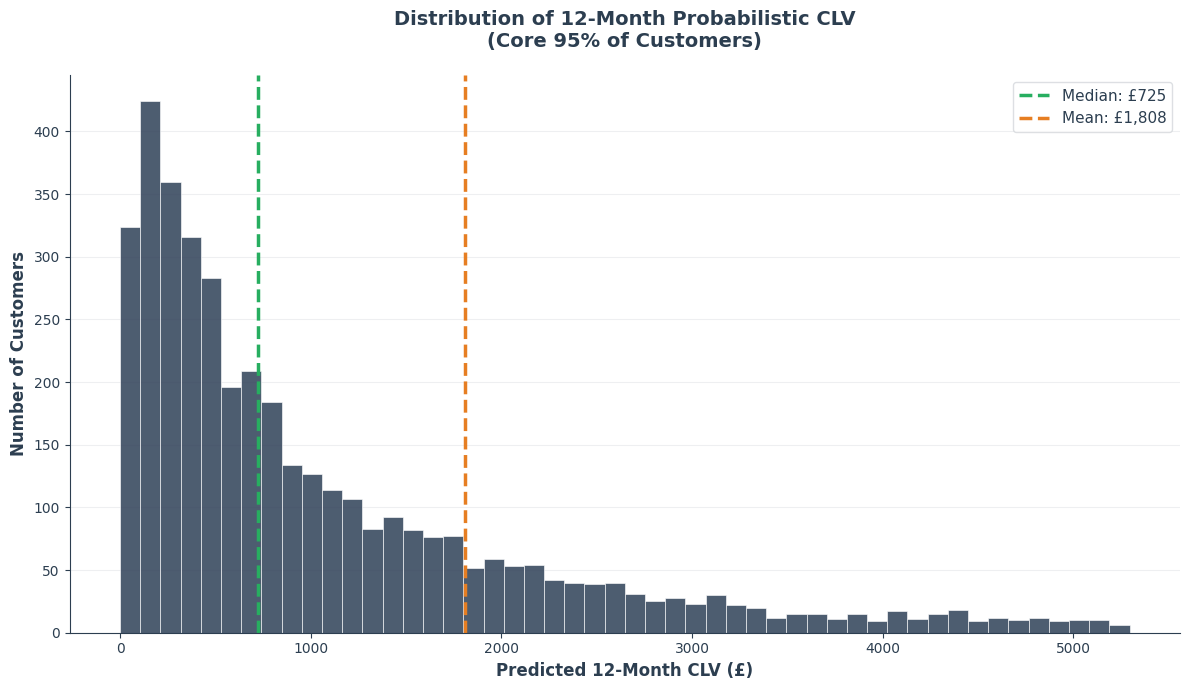


Value concentration:
Top 10% of customers by CLV: 3,461+
Top 10% CLV share: 55.5%


In [6]:
# Distribution visualization 
fig, ax = plt.subplots(figsize = (12, 7))

# Focus on the core 95% of customers for readability
clv_cap = output_df["CLV_12m"].quantile(0.95)
subset_clv = output_df[output_df["CLV_12m"] < clv_cap]["CLV_12m"]

counts, bins, patches = ax.hist(subset_clv, 
                                 bins = 50, 
                                 color = COLOR_PRIMARY,
                                 edgecolor = 'white',
                                 alpha = 0.85,
                                 linewidth = 0.5)

# Add mean and median reference lines
mean_clv = output_df["CLV_12m"].mean()
median_clv = output_df["CLV_12m"].median()

ax.axvline(median_clv, color = COLOR_ACCENT, linestyle = '--', linewidth = 2.5, 
           label = f'Median: £{median_clv:,.0f}')
ax.axvline(mean_clv, color = COLOR_SECONDARY, linestyle = '--', linewidth = 2.5,
           label = f'Mean: £{mean_clv:,.0f}')

ax.set_title("Distribution of 12-Month Probabilistic CLV\n(Core 95% of Customers)", 
             fontsize = 14, fontweight = 'bold', pad = 20)
ax.set_xlabel("Predicted 12-Month CLV (£)", fontsize = 12, fontweight = 'semibold')
ax.set_ylabel("Number of Customers", fontsize = 12, fontweight = 'semibold')
ax.grid(True, axis = 'y', alpha = 0.4)
ax.set_axisbelow(True)
ax.legend(frameon = True, facecolor = 'white', edgecolor = COLOR_GRID, fontsize = 11)

plt.tight_layout()
plt.show()

# Print concentration metrics
top_10_pct = output_df["CLV_12m"].quantile(0.90)
top_10_rev = output_df[output_df["CLV_12m"] >= top_10_pct]["CLV_12m"].sum()
total_rev = output_df["CLV_12m"].sum()
print(f"\nValue concentration:")
print(f"Top 10% of customers by CLV: {top_10_pct:,.0f}+")
print(f"Top 10% CLV share: {top_10_rev/total_rev:.1%}")

## Exporting Probabilistic CLV Results

The 12-month probabilistic CLV estimates are exported as a customer-level dataset for downstream use. Each row contains a unique customer identifier alongside their predicted CLV and the underlying model inputs (frequency, recency, tenure, average monetary value), enabling consistent reuse across segmentation, targeting simulations, and BI reporting.

Customers excluded from Gamma-Gamma estimation (one-time buyers) are not included in this export. They will be addressed in the segmentation notebook where their future potential can be assessed through alternative means.

In [7]:
file_name = "customers_clv_probabilistic_12m.csv"
output_df.to_csv(file_name, index = False)
print(f"Saved: {file_name}")
print(f"Records: {len(output_df):,}")

Saved: customers_clv_probabilistic_12m.csv
Records: 4,171
